# Supplementary Figure 9. Sensitivity of converged TCN response rates to normal initialization


In [1]:
%matplotlib inline
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.environ.setdefault("SIM_RUN_MODE", "production")
%run ./simulation_core.ipynb

OUTPUT_ROOT, FIGURE_DIR, SOURCE_DIR = make_output_dirs("Supplementary_Figure_9_outputs")
PCN_CAPACITY_GRID=(np.array([100],dtype=int) if RUN_MODE=="quick" else np.arange(20,101,4,dtype=int))
SETTINGS={
 "loss mean 90%, sd 5%":("loss",0.90,0.05), "loss mean 90%, sd 10%":("loss",0.90,0.10),
 "loss mean 70%, sd 5%":("loss",0.70,0.05), "loss mean 70%, sd 10%":("loss",0.70,0.10),
 "gain mean 10%, sd 5%":("gain",0.10,0.05), "gain mean 10%, sd 10%":("gain",0.10,0.10),
 "gain mean 30%, sd 5%":("gain",0.30,0.05), "gain mean 30%, sd 10%":("gain",0.30,0.10),
}
CONDITIONS=("transposition on","transposition off")


In [2]:
rows=[]
for setting,(family,mean,sd) in SETTINGS.items():
    for max_pcn in PCN_CAPACITY_GRID:
        configs={c.condition:c for c in standard_configurations(int(max_pcn))}
        init=normal_initial_state(int(max_pcn),mean_fraction_of_pcn=mean,sd_fraction_of_pcn=sd)
        for condition in CONDITIONS:
            r=evaluate_configuration(int(max_pcn),configs[condition],initial_state=init.copy())
            r.update({"initialization":setting,"family":family,"mean_fraction":mean,"sd_fraction":sd})
            rows.append(r)
results=pd.DataFrame(rows)

blocks=[("loss","loss_rate",[(0.90,0.05),(0.90,0.10),(0.70,0.05),(0.70,0.10)]),
        ("gain","gain_rate",[(0.10,0.05),(0.10,0.10),(0.30,0.05),(0.30,0.10)])]

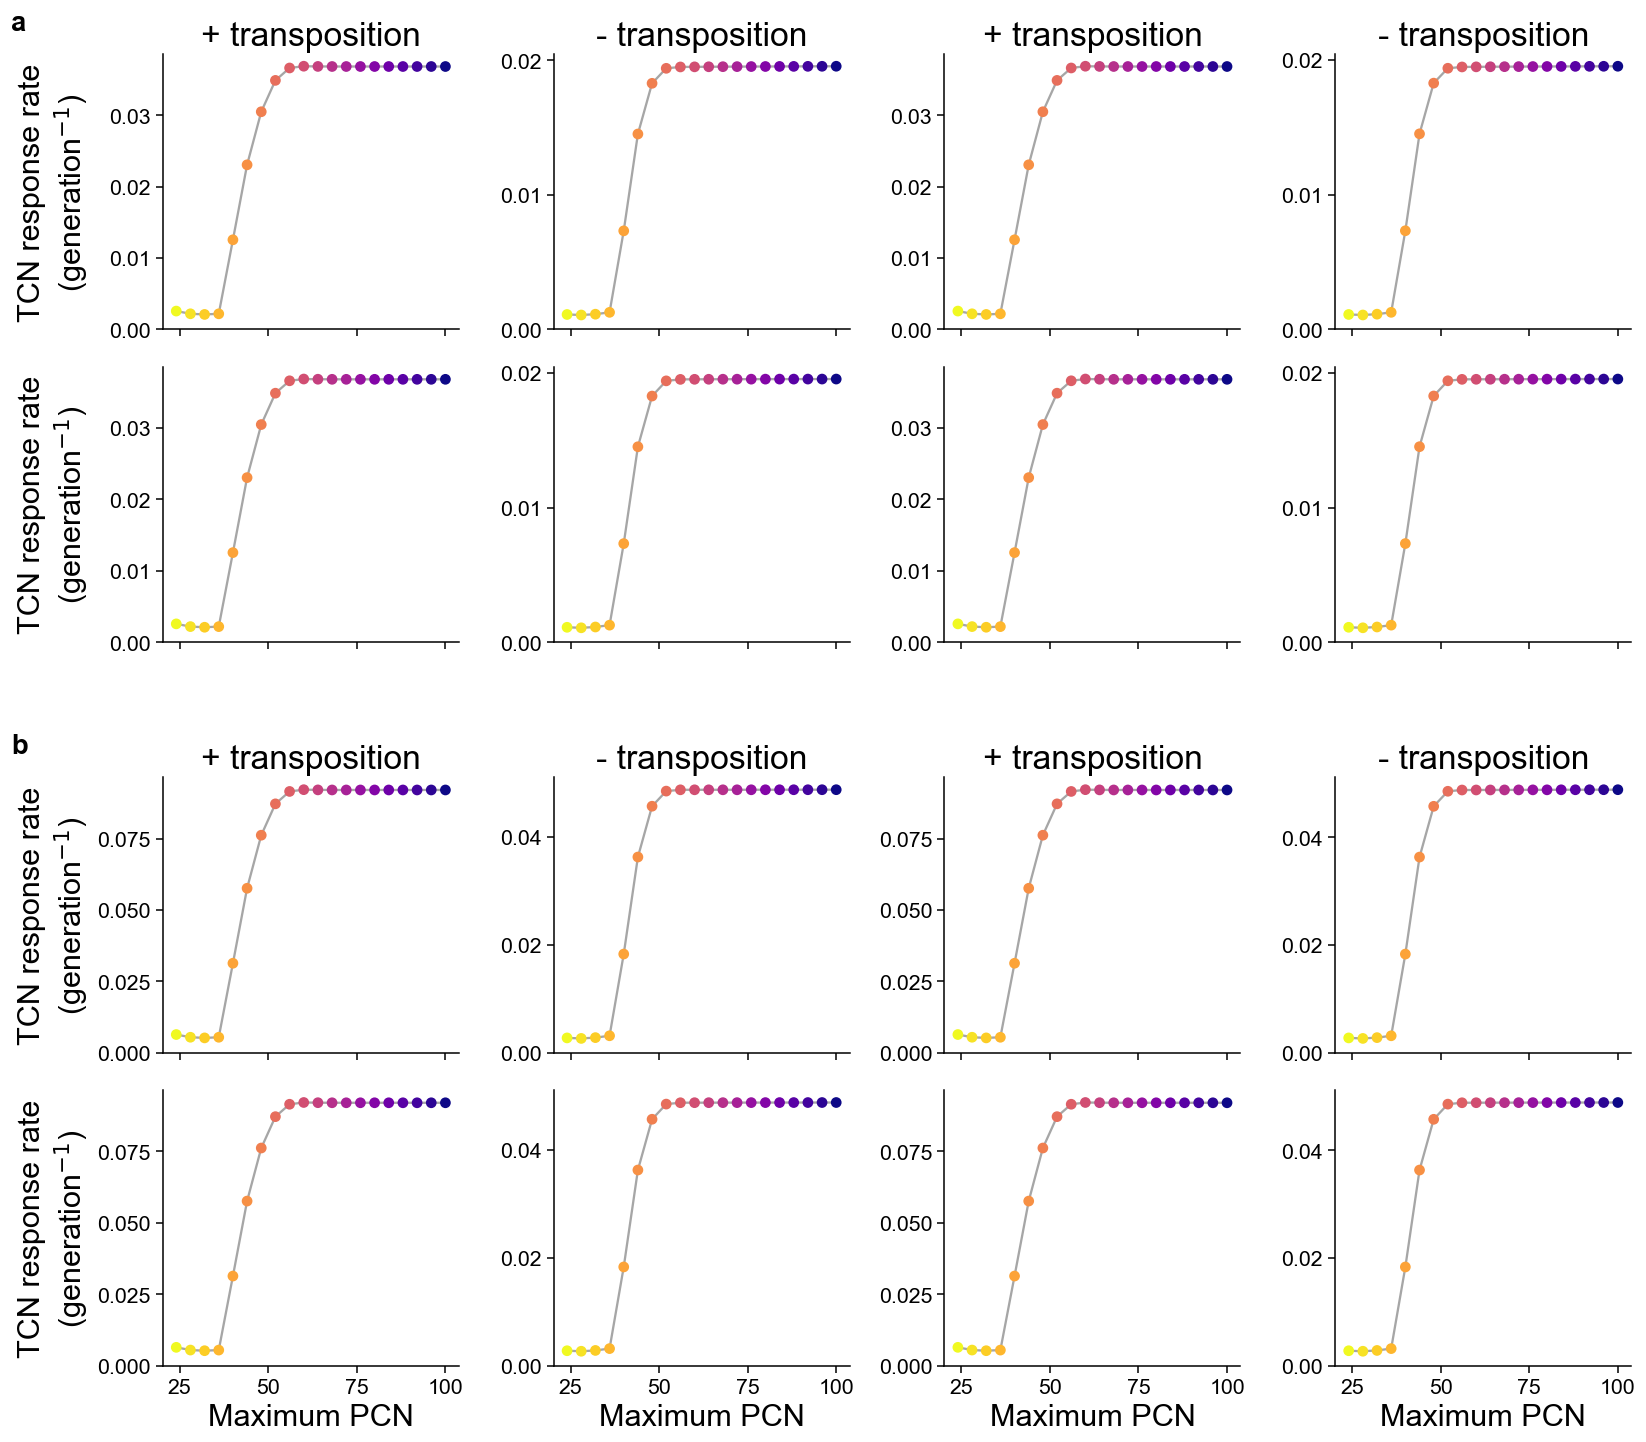

In [4]:
plt.rcParams.update(PLOT_STYLE)
LARGE_FONT_STYLE = {
    "font.size": 14, "axes.labelsize": 20, "axes.titlesize": 22,
    "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 15,
    "axes.linewidth": 1.0, "xtick.major.width": 1.0, "ytick.major.width": 1.0,
    "xtick.major.size": 4.5, "ytick.major.size": 4.5,
}
plt.rcParams.update(LARGE_FONT_STYLE)
PANEL_FONT = 18
fig=plt.figure(figsize=(15.0,13.4))

gs=fig.add_gridspec(5,4,height_ratios=[1,1,0.22,1,1],left=0.10,right=0.99,
                    bottom=0.065,top=0.955,wspace=0.32,hspace=0.16)
axes=np.empty((4,4),dtype=object)
for row,grow in enumerate((0,1,3,4)):
    for col in range(4):
        axes[row,col]=fig.add_subplot(gs[grow,col],sharex=axes[0,col] if row else None)
for bi,(family,metric,pairs) in enumerate(blocks):
    for mean,sd in pairs:
        row=bi*2+(0 if sd==0.05 else 1)
        for ci,condition in enumerate(CONDITIONS):
            col=(0 if mean in (0.90,0.10) else 2)+ci
            ax=axes[row,col]
            d=results[(results.family==family)&(results.mean_fraction==mean)&(results.sd_fraction==sd)&(results.condition==condition)&results.response_valid].sort_values("maximum_PCN")
            ax.plot(d.maximum_PCN,d[metric],color="0.65",lw=1.5)
            ax.scatter(d.maximum_PCN,d[metric],c=d.maximum_PCN,cmap="plasma_r",s=36,zorder=3)
            ax.set_ylim(bottom=0)
            ax.locator_params(axis="y",nbins=4)
            if row==3: ax.set_xlabel("Maximum PCN")
            else: ax.tick_params(axis="x",labelbottom=False)
            if col==0: ax.set_ylabel("TCN response rate\n(generation$^{-1}$)")
            if row in (0,2): ax.set_title("+ transposition" if condition=="transposition on" else "- transposition")
fig.align_ylabels(axes[:,0])
for row,letter in ((0,"a"),(2,"b")):
    p=axes[row,0].get_position()
    fig.text(0.008,p.y1+0.012,letter,fontweight="bold",fontsize=PANEL_FONT,va="bottom",ha="left")
save_figure(fig,"Supplementary_Figure_9_normal_initialization",FIGURE_DIR); plt.show()

export_table(results,"Supplementary_Figure_9_source_data.csv",SOURCE_DIR)
export_table(core_metadata("Supplementary Figure 9"),"Supplementary_Figure_9_run_metadata.csv",SOURCE_DIR)
